In [ ]:
# Implement and compare hierarchical (agglomerative) and partitional (K-means) clustering
# algorithms on the Mall Customers dataset. Discuss the strengths and weaknesses of each
# method based on clustering results and evaluation metrics.
# Tasks:
# ● Load and preprocess the Mall Customers dataset.
# ● Apply both hierarchical (agglomerative) and K-means clustering.
# ● Compare results using metrics such as inertia, silhouette score, and clustering visualization.
# ● Discuss the advantages and disadvantages of each clustering method.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [3]:
data = pd.read_csv("./Mall_Customers.csv")
data

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [24]:
x = data[['Annual Income (k$)','Spending Score (1-100)']]
x_scaled = StandardScaler().fit_transform(x)
x.columns

Index(['Annual Income (k$)', 'Spending Score (1-100)'], dtype='str')

In [21]:
kmeans = KMeans(n_clusters = 5,random_state = 42)
k_pred = kmeans.fit_predict(x_scaled)
print("KMeans Inertia = ",kmeans.inertia_)
print("KMeans Silhouette =",silhouette_score(x_scaled,k_pred))

KMeans Inertia =  65.56840815571681
KMeans Silhouette = 0.5546571631111091


C:\Users\amaln\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [22]:
agg = AgglomerativeClustering(n_clusters = 5)
agg_pred = agg.fit_predict(x_scaled)
print("Agglomerative Silhouette =",silhouette_score(x_scaled,agg_pred))

Agglomerative Silhouette = 0.5538089226688662


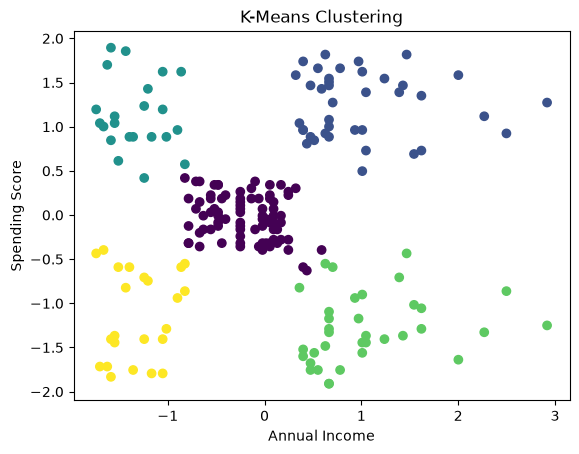

In [33]:
# Scatter plots

plt.scatter(x_scaled[:,0],x_scaled[:,1],c = k_pred)
plt.title("K-Means Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

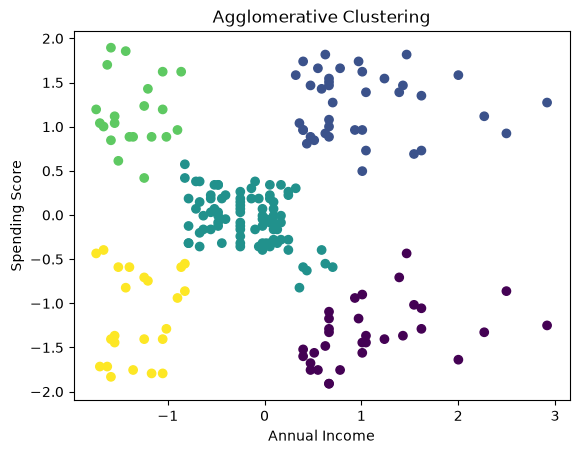

In [34]:
plt.scatter(x_scaled[:,0],x_scaled[:,1],c = agg_pred)
plt.title("Agglomerative Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()